# CountZES — Spike Test & Playground (Google Colab + Drive Mount)

Notebook dùng để **thử nghiệm tự do (spike test)** trên ảnh bất kỳ (URL, ảnh có sẵn trong `MyDrive/CountZES/data/`, hoặc ảnh upload từ máy) với prompt class tự do.

Toàn bộ data, weights và output dùng chung thư mục Google Drive: `/content/drive/MyDrive/CountZES/`.

In [1]:
# [CELL-1] Thiết lập môi trường, clone/pull repo (hỗ trợ cả Public & Private) & cài thư viện
import os, getpass, subprocess
os.environ["TORCH_FORCE_NO_WEIGHTS_ONLY_LOAD"] = "1"

REPO_OWNER_PATH = "github.com/duylw/cv-advanced.git"
REPO_URL = f"https://{REPO_OWNER_PATH}"
REPO_DIR = "/content/cv-advanced"

if not os.path.exists(os.path.join(REPO_DIR, ".git")):
    env_no_prompt = {**os.environ, "GIT_TERMINAL_PROMPT": "0"}
    res = subprocess.run(["git", "clone", REPO_URL, REPO_DIR], env=env_no_prompt)
    if res.returncode != 0:
        print("Repo đang ở chế độ Private -> nhập GitHub PAT (token không được lưu vào file):")
        token = os.environ.get("GITHUB_TOKEN") or getpass.getpass("GitHub PAT: ")
        subprocess.run(["git", "clone", f"https://{token}@{REPO_OWNER_PATH}", REPO_DIR], check=True)
        subprocess.run(["git", "-C", REPO_DIR, "remote", "set-url", "origin", REPO_URL], check=True)
else:
    env_no_prompt = {**os.environ, "GIT_TERMINAL_PROMPT": "0"}
    res = subprocess.run(["git", "-C", REPO_DIR, "pull", "origin", "main"], env=env_no_prompt)
    if res.returncode != 0:
        token = os.environ.get("GITHUB_TOKEN") or getpass.getpass("GitHub PAT: ")
        subprocess.run(["git", "-C", REPO_DIR, "pull", f"https://{token}@{REPO_OWNER_PATH}", "main"], check=True)

%cd {REPO_DIR}

!python -c "import addict, yapf, pycocotools, termcolor, yaml, gdown, supervision, timm, einops" 2>/dev/null || pip install -q opencv-python tqdm matplotlib timm einops supervision sentencepiece accelerate scipy pandas scikit-image addict yapf pycocotools termcolor pyyaml gdown "transformers>=4.31.0"
!python -c "import segment_anything" 2>/dev/null || pip install -q git+https://github.com/facebookresearch/segment-anything.git
!nvidia-smi

/content/cv-advanced
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Sat Nov 21 18:46:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   47C    P8              9W /   70W |       0MiB /  15360MiB |      0%

In [2]:
# [CELL-2] Mount Google Drive (/content/drive/MyDrive/CountZES) chứa cả data & weights
import shutil
from google.colab import drive

drive.mount("/content/drive")

DRIVE_PROJECT_DIR = "/content/drive/MyDrive/CountZES"
DRIVE_DATA_DIR = os.path.join(DRIVE_PROJECT_DIR, "data")
DRIVE_WEIGHTS_DIR = os.path.join(DRIVE_PROJECT_DIR, "weights")
DRIVE_OUTPUTS_DIR = os.path.join(DRIVE_PROJECT_DIR, "outputs")

for d in [DRIVE_PROJECT_DIR, DRIVE_DATA_DIR, DRIVE_WEIGHTS_DIR, DRIVE_OUTPUTS_DIR]:
    os.makedirs(d, exist_ok=True)

# Copy metadata (.json/.txt) từ repo sang Drive nếu Drive chưa có (idempotent, không ghi đè)
for root, _, files_in_dir in os.walk("/content/cv-advanced/data", followlinks=False):
    rel_root = os.path.relpath(root, "/content/cv-advanced/data")
    target_root = os.path.join(DRIVE_DATA_DIR, rel_root) if rel_root != "." else DRIVE_DATA_DIR
    os.makedirs(target_root, exist_ok=True)
    for fname in files_in_dir:
        src_f = os.path.join(root, fname)
        dst_f = os.path.join(target_root, fname)
        if not os.path.islink(src_f) and not os.path.exists(dst_f):
            shutil.copy2(src_f, dst_f)

os.makedirs("DSALVANet/checkpoints", exist_ok=True)
os.makedirs("GroundingDINO/weights", exist_ok=True)
os.makedirs("CounTR/output_allnew_dir", exist_ok=True)

def ensure_weight(weight_name, local_path, download_cmd=None):
    drive_path = os.path.join(DRIVE_WEIGHTS_DIR, weight_name)
    if not (os.path.exists(drive_path) and os.path.getsize(drive_path) > 0):
        if download_cmd:
            print(f"[Download -> Drive] {drive_path}")
            get_ipython().system(download_cmd.format(dst=drive_path))
        else:
            return
    else:
        print(f"[Drive OK] {drive_path}")
    if not (os.path.exists(drive_path) and os.path.getsize(drive_path) > 0):
        print(f"[WARNING] Chưa tải được {weight_name}. Hãy tải bằng trình duyệt rồi đặt vào: {drive_path}")
        return
    if os.path.islink(local_path) or os.path.exists(local_path):
        os.remove(local_path)
    os.symlink(drive_path, local_path)

ensure_weight(
    "sam_vit_h_4b8939.pth",
    "data/sam_vit_h_4b8939.pth",
    "wget -q --show-progress -O '{dst}' https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth"
)
ensure_weight(
    "checkpoint_200.pth",
    "DSALVANet/checkpoints/checkpoint_200.pth",
    "gdown 1julzH9MJSK1xTGchb1r0CXdZ2wzF5-Kp -O '{dst}'"
)
ensure_weight(
    "groundingdino_swint_ogc.pth",
    "GroundingDINO/weights/groundingdino_swint_ogc.pth",
    "gdown 13rV6dzRwWCVZYWpnmiaVwRDIDC28d82g -O '{dst}'"
)
ensure_weight("FSC147.pth", "CounTR/output_allnew_dir/FSC147.pth")
ensure_weight("CARPK.pth", "CounTR/output_allnew_dir/CARPK.pth")

print("Project Drive Dir:", DRIVE_PROJECT_DIR)

Mounted at /content/drive
[Drive OK] /content/drive/MyDrive/CountZES/weights/sam_vit_h_4b8939.pth
[Drive OK] /content/drive/MyDrive/CountZES/weights/checkpoint_200.pth
[Drive OK] /content/drive/MyDrive/CountZES/weights/groundingdino_swint_ogc.pth
Project Drive Dir: /content/drive/MyDrive/CountZES


In [3]:
# [CELL-3] Load toàn bộ 5 model 1 lần từ weights trên Drive + Log CPU/RAM/VRAM
import gc, torch
from types import SimpleNamespace
from countzes_core import load_pipeline_models
from resource_monitor import get_hardware_summary, monitor_resources

if "models" in globals():
    del models
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

RESOURCE_LOG_DIR = os.path.join(DRIVE_OUTPUTS_DIR, "logs")
print("Hardware info:", get_hardware_summary())
print(f"Resource logs -> {RESOURCE_LOG_DIR}/resource_usage.{{log,jsonl}}")

FSOC_BACKEND = "DSALVANet"  # "DSALVANet" hoặc "countr"
args = SimpleNamespace(
    data=DRIVE_DATA_DIR,
    outdir="spike_test",
    ckpt=os.path.join(DRIVE_WEIGHTS_DIR, "sam_vit_h_4b8939.pth"),
    sam_type="vit_h",
    ref_idx="00",
    visualize=True,
    fsoc=FSOC_BACKEND,
    weight=os.path.join(DRIVE_WEIGHTS_DIR, "checkpoint_200.pth"),
    countr_ckpt=os.path.join(DRIVE_WEIGHTS_DIR, "FSC147.pth"),
    fix_sses_inversion=False,
    single_instance_mode="paper",
)
with monitor_resources(
    "load_models",
    log_dir=RESOURCE_LOG_DIR,
    metadata={"fsoc": FSOC_BACKEND, "sam_type": args.sam_type},
):
    models = load_pipeline_models(args)
print("Models loaded on:", models["device"])

======> Load SAM
======> Done
======> Load Grounding Detector
final text_encoder_type: bert-base-uncased


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

... (17 outputs left out)

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

======> Done
Downloading: "https://github.com/wimmerth/anyup/zipball/main" to /root/.cache/torch/hub/main.zip
Downloading: "https://github.com/wimmerth/anyup/releases/download/checkpoint/anyup_paper.pth" to /root/.cache/torch/hub/checkpoints/anyup_paper.pth


100%|██████████| 3.38M/3.38M [00:00<00:00, 97.9MB/s]

Models loaded on: cuda


In [8]:
# [CELL-4] Chọn ảnh thử nghiệm: từ URL, từ Google Drive (MyDrive/CountZES/data/), hoặc upload từ máy
import urllib.request

IMAGE_SOURCE = "url"   # "url" | "drive" | "upload"
CLASS_PROMPT = "oranges"  # Đổi tên object khớp ảnh (vd: "oranges", "cars", "apples", "cells")

# Dùng khi IMAGE_SOURCE == "url" (mặc định: ảnh cam kinh điển của repo FSC-147/FamNet, rất dễ kiểm tra từng giai đoạn)
TEST_IMAGE_URL = "https://raw.githubusercontent.com/cvlab-stonybrook/LearningToCountEverything/master/orange.jpg"

# Dùng khi IMAGE_SOURCE == "drive" (đường dẫn tương đối bên trong MyDrive/CountZES/data/)
DRIVE_REL_IMAGE = "vgg/Images/cells/00.png"

os.makedirs(os.path.join(DRIVE_OUTPUTS_DIR, "spike_inputs"), exist_ok=True)

if IMAGE_SOURCE == "url":
    fname = os.path.basename(TEST_IMAGE_URL.split("?")[0]) or "test_sample.jpg"
    TEST_IMAGE_PATH = os.path.join(DRIVE_OUTPUTS_DIR, "spike_inputs", fname)
    req = urllib.request.Request(TEST_IMAGE_URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=30) as resp, open(TEST_IMAGE_PATH, "wb") as f:
        f.write(resp.read())
elif IMAGE_SOURCE == "drive":
    TEST_IMAGE_PATH = os.path.join(DRIVE_DATA_DIR, DRIVE_REL_IMAGE)
elif IMAGE_SOURCE == "upload":
    from google.colab import files
    uploaded = files.upload()
    TEST_IMAGE_PATH = list(uploaded.keys())[0]
else:
    raise ValueError(f"Unsupported IMAGE_SOURCE: {IMAGE_SOURCE}")

assert os.path.exists(TEST_IMAGE_PATH), f"Không tìm thấy ảnh: {TEST_IMAGE_PATH}"
print(f"Test image -> {TEST_IMAGE_PATH} | Prompt: '{CLASS_PROMPT}'")

Test image -> /content/drive/MyDrive/CountZES/outputs/spike_inputs/orange.jpg | Prompt: 'oranges'


Target object: ['oranges']
==> Predicted Count for 'oranges': 41


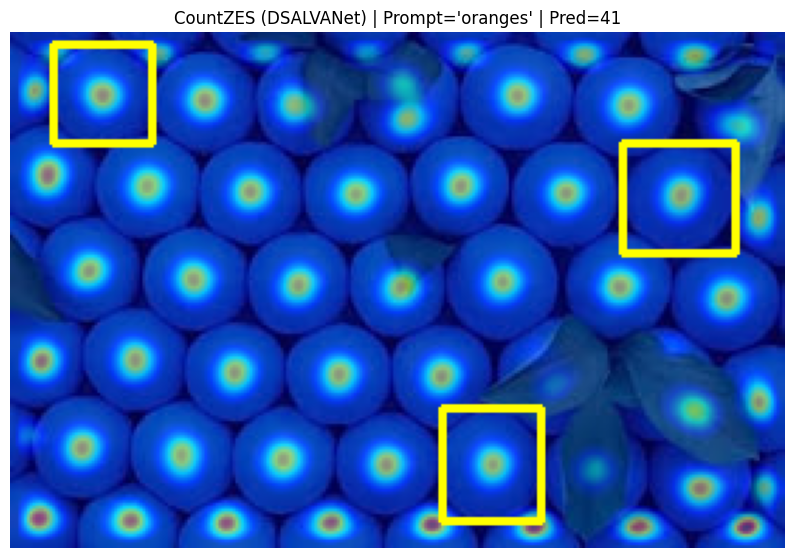

In [9]:
# [CELL-5] Chạy nhanh CountZES, đo CPU/RAM/VRAM và xem kết quả cuối
import os
import cv2
import matplotlib.pyplot as plt
from countzes_core import run_countzes_on_image
from resource_monitor import monitor_resources

_log_dir = globals().get("RESOURCE_LOG_DIR") or os.path.join(DRIVE_OUTPUTS_DIR, "logs")
with monitor_resources(
    "inference_single",
    log_dir=_log_dir,
    metadata={"image": os.path.basename(TEST_IMAGE_PATH), "class": CLASS_PROMPT, "fsoc": args.fsoc},
):
    vis_output, pred_count = run_countzes_on_image(
        image_path=TEST_IMAGE_PATH,
        filename=os.path.basename(TEST_IMAGE_PATH),
        class_name=CLASS_PROMPT,
        models=models,
        args=args,
    )

print(f"==> Predicted Count for '{CLASS_PROMPT}': {pred_count}")
plt.figure(figsize=(10, 7))
plt.imshow(cv2.cvtColor(vis_output, cv2.COLOR_BGR2RGB))
plt.title(f"CountZES ({args.fsoc}) | Prompt='{CLASS_PROMPT}' | Pred={pred_count}")
plt.axis("off")
plt.show()

Target object: ['oranges']
Target object: ['oranges']
=== TÓM TẮT TỪNG GIAI ĐOẠN (PAPER MODE) ===
Stage 1 | GDINO boxes: 17 | initial_box: [217, 39, 257, 78] | DAE (green): [217, 39, 257, 78]
Stage 2 | Density1 count: 38 | P2P pts: 49 | SAM boxes: 67 | single1: 10 | pseudo_gt(KDE): 40 | DGE (blue): [15, 4, 50, 39]
Stage 3 | Density2 count: 41 | P2P pts: 51 | filtered: 50 | single2: 10 | FCE (red): [153, 133, 188, 173]
Final   | Paper Pred: 41 | A/B P2-Fix Pred: 37 (A/B exemplars: DAE=[217, 39, 257, 78], DGE=[178, 39, 215, 75], FCE=[67, 39, 102, 75])


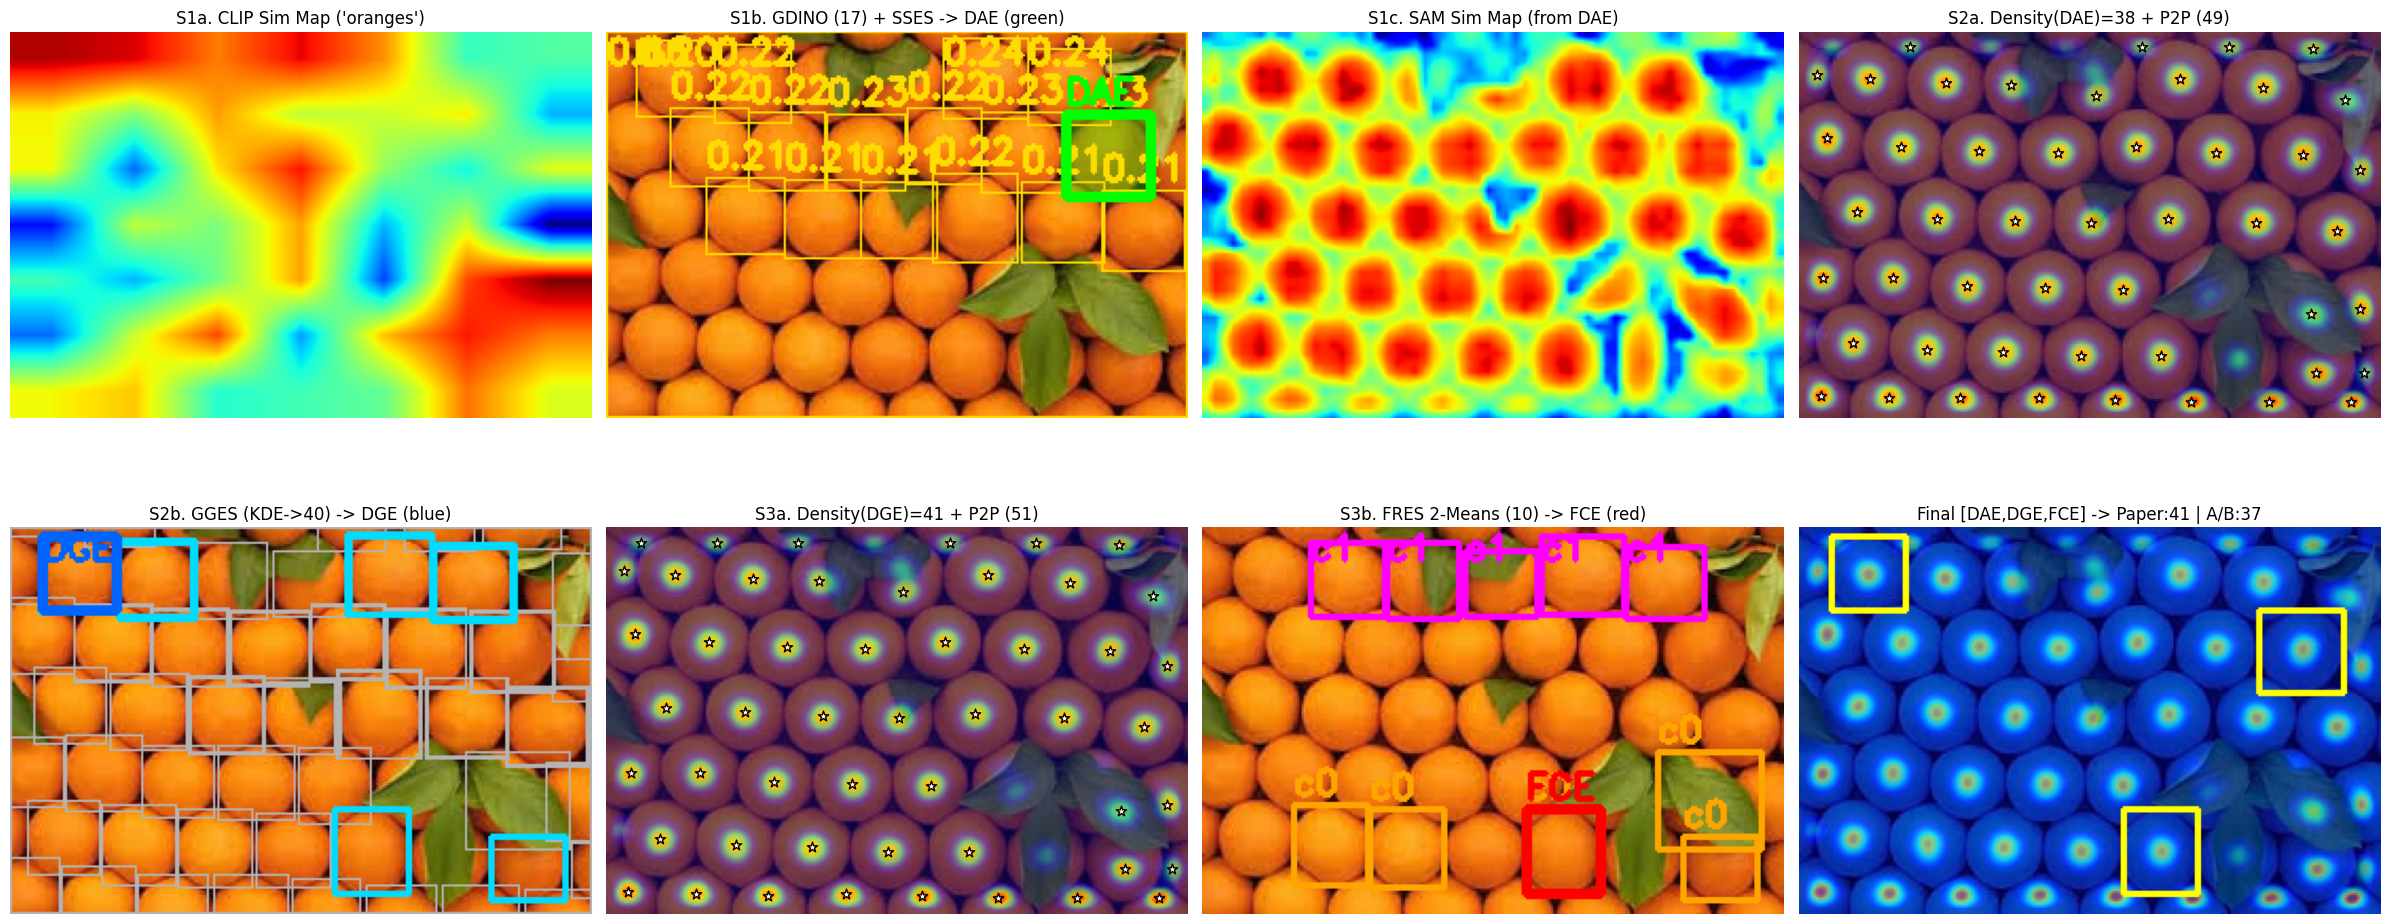

In [10]:
# [CELL-6] Soi chi tiết từng giai đoạn (Paper S1 -> S2 -> S3 -> Final 2x4 + A/B P2 flags)
%matplotlib inline
import os
from types import SimpleNamespace
import cv2
import matplotlib.pyplot as plt
import numpy as np
from countzes_core import run_countzes_on_image
from resource_monitor import monitor_resources

_log_dir = globals().get("RESOURCE_LOG_DIR") or os.path.join(DRIVE_OUTPUTS_DIR, "logs")
_meta = {"image": os.path.basename(TEST_IMAGE_PATH), "class": CLASS_PROMPT, "fsoc": args.fsoc}

with monitor_resources("inference_stage_debug_paper", log_dir=_log_dir, metadata={**_meta, "mode": "paper"}):
    vis_paper, pred_paper, dbg = run_countzes_on_image(
        image_path=TEST_IMAGE_PATH,
        filename=os.path.basename(TEST_IMAGE_PATH),
        class_name=CLASS_PROMPT,
        models=models,
        args=args,
        return_debug=True,
    )

args_ab = SimpleNamespace(**vars(args))
args_ab.fix_sses_inversion = True
args_ab.single_instance_mode = "unit"
with monitor_resources("inference_stage_debug_ab", log_dir=_log_dir, metadata={**_meta, "mode": "ab_p2_fix"}):
    vis_ab, pred_ab, dbg_ab = run_countzes_on_image(
        image_path=TEST_IMAGE_PATH,
        filename=os.path.basename(TEST_IMAGE_PATH),
        class_name=CLASS_PROMPT,
        models=models,
        args=args_ab,
        return_debug=True,
    )

print(f"Log tài nguyên đã ghi -> {_log_dir}/resource_usage.{{log,jsonl}}")

def _draw_box(img, box, color, label=None, thickness=2):
    if box is None or len(box) != 4:
        return
    x0, y0, x1, y1 = [int(v) for v in box]
    cv2.rectangle(img, (x0, y0), (x1, y1), color, thickness)
    if label:
        cv2.putText(img, label, (x0, max(15, y0 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.55, color, 2)

img_rgb = dbg["img_rgb"]

# --- Bảng tóm tắt số liệu từng giai đoạn ---
print("=== TÓM TẮT TỪNG GIAI ĐOẠN (PAPER MODE) ===")
print(f"Stage 1 | GDINO boxes: {len(dbg['gdino_boxes'])} | initial_box: {dbg['initial_box']} | DAE (green): {dbg['dae']}")
print(f"Stage 2 | Density1 count: {dbg['count_stage2']} | P2P pts: {len(dbg['point_prompts_stage2'])} | SAM boxes: {len(dbg['box_list_stage2'])} | single1: {len(dbg['single_instance_boxes1'])} | pseudo_gt(KDE): {dbg['pseudo_gt_count']} | DGE (blue): {dbg['dge']}")
print(f"Stage 3 | Density2 count: {dbg['count_stage3']} | P2P pts: {len(dbg['point_prompts_stage3'])} | filtered: {len(dbg['filtered_boxes'])} | single2: {len(dbg['single_instance_boxes'])} | FCE (red): {dbg['fce']}")
print(f"Final   | Paper Pred: {pred_paper} | A/B P2-Fix Pred: {pred_ab} (A/B exemplars: DAE={dbg_ab['dae']}, DGE={dbg_ab['dge']}, FCE={dbg_ab['fce']})")

# --- Panel S1b: GDINO + SSES -> DAE ---
vis_s1b = img_rgb.copy()
if dbg["dae_mask"] is not None:
    mask_bool = dbg["dae_mask"].astype(bool)
    vis_s1b[mask_bool] = (0.65 * vis_s1b[mask_bool] + 0.35 * np.array([0, 255, 0])).astype(np.uint8)
for b, c in zip(dbg["gdino_boxes"], dbg["gdino_confs"]):
    _draw_box(vis_s1b, b, (255, 220, 0), f"{c:.2f}", 1)
_draw_box(vis_s1b, dbg["initial_box"], (255, 128, 0), "init", 2)
_draw_box(vis_s1b, dbg["dae"], (0, 255, 0), "DAE", 3)

# --- Panel S2b: GGES (KDE) -> DGE ---
vis_s2b = img_rgb.copy()
for b in dbg["box_list_stage2"]:
    _draw_box(vis_s2b, b, (180, 180, 180), None, 1)
for b in dbg["single_instance_boxes1"]:
    _draw_box(vis_s2b, b, (0, 220, 255), None, 2)
_draw_box(vis_s2b, dbg["dge"], (0, 100, 255), "DGE", 3)

# --- Panel S3b: FRES 2-Means -> FCE ---
vis_s3b = img_rgb.copy()
for b, lbl in zip(dbg["single_instance_boxes"], dbg["kmeans_labels"]):
    col = (255, 165, 0) if lbl == 0 else (255, 0, 255)
    _draw_box(vis_s3b, b, col, f"c{lbl}", 2)
_draw_box(vis_s3b, dbg["fce"], (255, 0, 0), "FCE", 3)

# --- Vẽ lưới 2 x 4 (8 khung hình) ---
fig, axes = plt.subplots(2, 4, figsize=(24, 11))

axes[0, 0].imshow(dbg["sim_clip"], cmap="jet")
axes[0, 0].set_title(f"S1a. CLIP Sim Map ('{CLASS_PROMPT}')")

axes[0, 1].imshow(vis_s1b)
axes[0, 1].set_title(f"S1b. GDINO ({len(dbg['gdino_boxes'])}) + SSES -> DAE (green)")

axes[0, 2].imshow(dbg["sim_up_dae"], cmap="jet")
axes[0, 2].set_title("S1c. SAM Sim Map (from DAE)")

axes[0, 3].imshow(img_rgb)
axes[0, 3].imshow(dbg["density_stage2"], cmap="jet", alpha=0.5)
if len(dbg["point_prompts_stage2"]) > 0:
    pts2 = np.array(dbg["point_prompts_stage2"])
    axes[0, 3].scatter(pts2[:, 0], pts2[:, 1], c="white", marker="*", s=60, edgecolors="black")
axes[0, 3].set_title(f"S2a. Density(DAE)={dbg['count_stage2']} + P2P ({len(dbg['point_prompts_stage2'])})")

axes[1, 0].imshow(vis_s2b)
axes[1, 0].set_title(f"S2b. GGES (KDE->{dbg['pseudo_gt_count']}) -> DGE (blue)")

axes[1, 1].imshow(img_rgb)
axes[1, 1].imshow(dbg["density_stage3"], cmap="jet", alpha=0.5)
if len(dbg["point_prompts_stage3"]) > 0:
    pts3 = np.array(dbg["point_prompts_stage3"])
    axes[1, 1].scatter(pts3[:, 0], pts3[:, 1], c="white", marker="*", s=60, edgecolors="black")
axes[1, 1].set_title(f"S3a. Density(DGE)={dbg['count_stage3']} + P2P ({len(dbg['point_prompts_stage3'])})")

axes[1, 2].imshow(vis_s3b)
axes[1, 2].set_title(f"S3b. FRES 2-Means ({len(dbg['single_instance_boxes'])}) -> FCE (red)")

axes[1, 3].imshow(cv2.cvtColor(vis_paper, cv2.COLOR_BGR2RGB))
axes[1, 3].set_title(f"Final [DAE,DGE,FCE] -> Paper:{pred_paper} | A/B:{pred_ab}")

for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()